# Charge transport in an amorphous thiophene morphology

This tutorial applies the transport calculators of VOTCA-XTP to a real morphology: 1000 thiophene molecules from a LAMMPS simulation, with site energies, electronic couplings and reorganization energies already in the state file `state.hdf5` (the workflow that produces them is shown in the QMMM tutorials). We look at the energy landscape and the couplings, compute bulk mobilities of electrons and holes, and run a time-of-flight calculation that shows where the carriers are held up.

For the methods and their options on a controlled model system, see the tutorial *Charge and exciton transport on a model lattice* and the chapter *Transport Simulations* of the manual.

## Requirements
* VOTCA installed and the environment activated with `VOTCARC.bash` (see the [installation instructions](https://github.com/votca/votca/blob/master/share/sphinx/INSTALL.rst)).
* Python with `numpy` and `matplotlib`.

In Jupyter, `!` runs a shell command.

In [1]:
import subprocess
import numpy as np
import matplotlib.pyplot as plt


def run(command):
    # run a VOTCA command quietly (raises if it fails)
    subprocess.run(command, shell=True, check=True, capture_output=True)


def results(filename):
    # read a 'key value unit' result file into a dictionary
    values = {}
    with open(filename) as f:
        for line in f:
            if line.startswith("#") or not line.strip():
                continue
            key, value = line.split()[:2]
            try:
                values[key] = float(value)
            except ValueError:
                values[key] = value
    return values

## Site energies and couplings

`eanalyze` writes histograms of the site energies and of the site energy differences of neighbouring pairs (here with a resolution of 0.03 eV); `ianalyze` writes the distribution of the couplings $\log_{10}|J|^2$. See [eanalyze](https://www.votca.org/xtp/eanalyze.html) and [ianalyze](https://www.votca.org/xtp/ianalyze.html) for the options.

In [2]:
!xtp_run -e eanalyze -c resolution_sites=0.03 -f state.hdf5
!xtp_run -e ianalyze -c resolution_logJ2=0.1 states=e,h -f state.hdf5

========   VOTCA (http://www.votca.org)   ========

please read and cite: https://doi.org/10.21105/joss.06864
and submit bugs to https://github.com/votca/votca/issues

xtp_run, version 2026-dev gitid: 07b3eb1 (compiled Oct 31 2026, 18:18:49)

Initializing calculator
... eanalyze
1 frames in statefile, Ids are: 10000 
Starting at frame 10000
Evaluating frame 10000
Import MD Topology (i.e. frame 10000) from state.hdf5


.... 


... eanalyze
 Using 1 threads
... ... Short-listed 1000 segments (pattern='*')
... ... ... NOTE Statistics of site energies and spatial correlations thereof are based on the short-listed segments only. 
... ... ...      Statistics of site-energy differences operate on the full list.
... ... excited state e
... ... excited state h


... ... excited state s


... ... excited state t
Changes have not been written to state file.

Please cite the methods used in this run:
  [1] Baumeier, Wehner, Renaud, Zapata Ruiz, Halver, Madhikar, Gerritsen, Tirimbo, Sijen, Rosenberger, Brown, Sundaram, Krajniak, Bernhardt, and Junghans, VOTCA: multiscale frameworks for quantum and classical simulations in soft matter, J. Open Source Softw. 9, 6864 (2024), doi:10.21105/joss.06864
  [2] Ruehle, Lukyanov, May, Schrader, Vehoff, Kirkpatrick, Baumeier, and Andrienko, Microscopic simulations of charge transport in disordered organic semiconductors, J. Chem. Theory Comput. 7, 3335 (2011), doi:10.1021/ct200388s


========   VOTCA (http://www.votca.org)   ========

please read and cite: https://doi.org/10.21105/joss.06864
and submit bugs to https://github.com/votca/votca/issues

xtp_run, version 2026-dev gitid: 07b3eb1 (compiled Oct 31 2026, 18:18:49)

Initializing calculator
... ianalyze
1 frames in statefile, Ids are: 10000 
Starting at frame 10000
Evaluating frame 10000
Import MD Topology (i.e. frame 10000) from state.hdf5


.... 


... ianalyze
 Using 1 threads
Calculating for state e now.
Calculating for state h now.
Changes have not been written to state file.

Please cite the methods used in this run:
  [1] Baumeier, Wehner, Renaud, Zapata Ruiz, Halver, Madhikar, Gerritsen, Tirimbo, Sijen, Rosenberger, Brown, Sundaram, Krajniak, Bernhardt, and Junghans, VOTCA: multiscale frameworks for quantum and classical simulations in soft matter, J. Open Source Softw. 9, 6864 (2024), doi:10.21105/joss.06864
  [2] Ruehle, Lukyanov, May, Schrader, Vehoff, Kirkpatrick, Baumeier, and Andrienko, Microscopic simulations of charge transport in disordered organic semiconductors, J. Chem. Theory Comput. 7, 3335 (2011), doi:10.1021/ct200388s


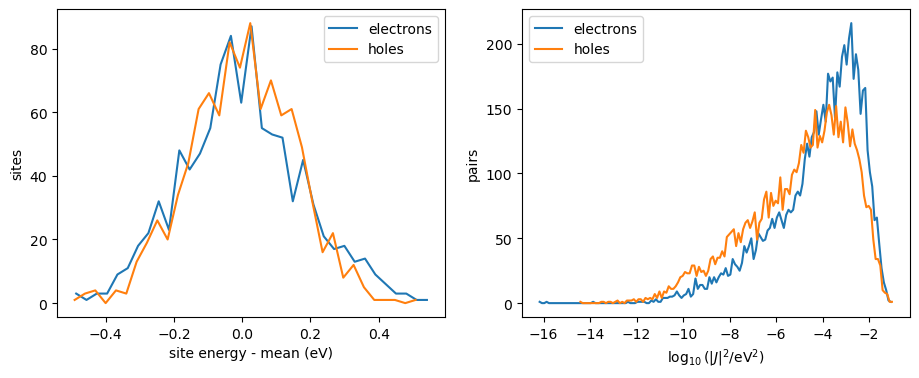

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
for carrier, label in [("e", "electrons"), ("h", "holes")]:
    hist = np.loadtxt(f"eanalyze.sitehist_{carrier}.out")
    ax1.plot(hist[:, 0] - np.average(hist[:, 0], weights=hist[:, 1]), hist[:, 1], label=label)
    coupling = np.loadtxt(f"ianalyze.ihist_{carrier}.out")
    ax2.plot(coupling[:, 0], coupling[:, 1], label=label)
ax1.set_xlabel("site energy - mean (eV)")
ax1.set_ylabel("sites")
ax1.legend()
ax2.set_xlabel(r"$\log_{10}(|J|^2/\mathrm{eV}^2)$")
ax2.set_ylabel("pairs")
ax2.legend()
plt.show()

The width of the site energy distribution (energetic disorder) controls how strongly carriers are trapped; the couplings span many orders of magnitude, so a few well-coupled pairs carry most of the current.

## Bulk mobility

`kmcmultiple` follows carriers in the periodic box. With one carrier, the exact single-carrier mobility from the master equation (printed with `exact`, the default) is the reference. Electrons drift against the field; the reported mobility is positive when carriers drift along the force on them. We use 8 independent runs of $10^7$ KMC events each.

In [4]:
!xtp_run -e kmcmultiple -c carriertype=electron field="1e7 0 0" numberofcarriers=1 runs=8 runtime=10000000 outputtime=0 -f state.hdf5

========   VOTCA (http://www.votca.org)   ========

please read and cite: https://doi.org/10.21105/joss.06864
and submit bugs to https://github.com/votca/votca/issues

xtp_run, version 2026-dev gitid: 07b3eb1 (compiled Oct 31 2026, 18:18:49)

Initializing calculator
... kmcmultiple
1 frames in statefile, Ids are: 10000 
Starting at frame 10000
Evaluating frame 10000
Import MD Topology (i.e. frame 10000) from state.hdf5


.... 


... kmcmultiple
 Using 1 threads
 ... 
-----------------------------------
      KMC FOR MULTIPLE CHARGES
-----------------------------------
 ... Bulk hopping graph (periodic in a, b and c, no sinks) for electrons
  sites: 1000 (0 of ignored types), hops: 20302
  injection sites: 1000
  detailed balance: no (max deviation of ln(w_ij/w_ji) 1.9946)
 ... Rates written to rates.dat
 ... 1 electron(s), density 0.00729374 nm^-3, 8 run(s), 1 thread(s)
 ... Each run stops after 10000000 KMC events (hops and attempts into occupied sites)
 ... Waiting times: exponential


 ... 80000000 hops, 0 attempts into occupied sites (0 %), 3.76617 s
 ... Observation window of run 0: 0 s to 2.37198e-05 s, 75 blocks of 3.13642e-07 s
 ... Drift velocity (nm/s): -7.988725e+06  2.235114e+06  1.460862e+06
    +- 6.466042e+05 7.033715e+05 6.789512e+05 (standard error over runs)
 ... Mobility along the field: 7.988725e-06 +- 6.466042e-07 cm^2/Vs (7.988725e+08 nm^2/Vs)
 ... Diffusion tensor (nm^2/s):
 3.316687e+07 -6.591711e+06 -1.206046e+06
-6.591711e+06  2.275115e+07  7.211564e+06
-1.206046e+06  7.211564e+06  2.073618e+07
 ...   +- (standard error over runs)
2.160451e+06 1.548844e+06 1.006109e+06
1.548844e+06 2.450047e+06 1.605369e+06
1.006109e+06 1.605369e+06 2.579289e+06
 ...   eigenvalue 1.378348e+07 nm^2/s, direction -1.942780e-01 -6.974892e-01  6.897571e-01
 ...   eigenvalue 2.530671e+07 nm^2/s, direction -5.343305e-01 -5.144376e-01 -6.707047e-01
 ...   eigenvalue 3.756402e+07 nm^2/s, direction  8.226463e-01 -4.988615e-01 -2.727458e-01


 ... Exact for one carrier (master equation, sparse LU, 1000 sites, backward error 1.750526e-15):
  drift velocity (nm/s): -8.398750e+06  2.339211e+06  6.119456e+05
  diffusion tensor (nm^2/s):
 3.033214e+07 -8.848943e+06 -2.237831e+06
-8.848943e+06  2.035675e+07  5.820395e+06
-2.237831e+06  5.820395e+06  2.226720e+07
 ...   mobility along the field: 8.398750e-06 cm^2/Vs
 ...   KMC - exact mobility: -6.341195e-01 standard errors
 ... Occupation probabilities written to occupation.datChanges have not been written to state file.

Please cite the methods used in this run:
  [1] Baumeier, Wehner, Renaud, Zapata Ruiz, Halver, Madhikar, Gerritsen, Tirimbo, Sijen, Rosenberger, Brown, Sundaram, Krajniak, Bernhardt, and Junghans, VOTCA: multiscale frameworks for quantum and classical simulations in soft matter, J. Open Source Softw. 9, 6864 (2024), doi:10.21105/joss.06864
  [2] Ruehle, Lukyanov, May, Schrader, Vehoff, Kirkpatrick, Baumeier, and Andrienko, Microscopic simulations of charge tran

In [5]:
r = results("kmcmultiple_results.dat")
print(f"KMC {r['mobility']:.2e} +- {r['mobility_error']:.1e} cm^2/Vs, exact {r['exact_mobility']:.2e} cm^2/Vs")

KMC 7.99e-06 +- 6.5e-07 cm^2/Vs, exact 8.40e-06 cm^2/Vs


The statistical error of the KMC is large: the carrier spends most of its time on a few low-energy molecules and leaves them rarely, so even $8\cdot10^7$ events contain few independent escapes. The exact value needs no sampling and is cheap; with a very short KMC part (`runtime=1000`) we use it to compare electrons and holes and to scan the field:

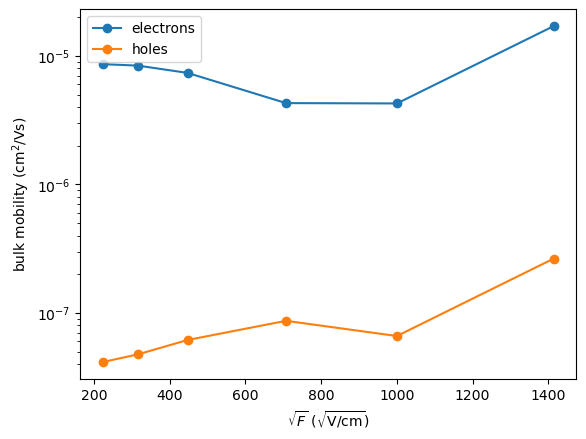

In [6]:
fields = np.array([0.5, 1, 2, 5, 10, 20]) * 1e7  # V/m
for carrier in ["electron", "hole"]:
    mu = []
    for F in fields:
        run(f'xtp_run -e kmcmultiple -c carriertype={carrier} field="{F} 0 0" runtime=1000 outputtime=0 resultfile=scan.dat ratefile=x occfile=x -f state.hdf5')
        mu.append(results("scan.dat")["exact_mobility"])
    plt.semilogy(np.sqrt(fields / 1e2), mu, "o-", label=carrier + "s")
plt.xlabel(r"$\sqrt{F}$ ($\sqrt{\mathrm{V/cm}}$)")
plt.ylabel("bulk mobility (cm$^2$/Vs)")
plt.legend()
plt.show()

Electrons are about two orders of magnitude more mobile than holes in this morphology. The irregular field dependence reflects the few low-energy sites that dominate transport in such a small box.

## Time of flight and trap sites

For a time-of-flight calculation the periodicity is cut across the box vector `a`; electrons are injected in a 1 nm slab at one face and collected at the other (the box is only about 5 nm long, so this is a very thin "sample"). Electrons move against the field, so the field points in $-x$. `grw` gives the mean time of flight exactly and, in `grw_occupation.dat`, the expected time $g_A$ each molecule holds the electron before it reaches the sink, and the *fraction of the time of flight* $g_A/\langle T\rangle$ (adding up to 1 over all molecules). All output quantities are defined in the section *Output quantities* of the manual chapter *Transport Simulations*.

In [7]:
!xtp_run -e grw -c carriertype=electron field="-1e7 0 0" -f state.hdf5

========   VOTCA (http://www.votca.org)   ========

please read and cite: https://doi.org/10.21105/joss.06864
and submit bugs to https://github.com/votca/votca/issues

xtp_run, version 2026-dev gitid: 07b3eb1 (compiled Oct 31 2026, 18:18:49)

Initializing calculator
... grw
1 frames in statefile, Ids are: 10000 
Starting at frame 10000
Evaluating frame 10000
Import MD Topology (i.e. frame 10000) from state.hdf5


.... 


... grw
 Using 1 threads
 ... 
-----------------------------------
  GRAPH RANDOM WALK TIME OF FLIGHT
-----------------------------------
 ... ToF graph for electrons
  periodicity cut across box vector a, normal (1 0 0), thickness 5.15644 nm
  sites: 1000 (0 of ignored types), hops: 18838, pairs cut at the periodic boundary: 732
  sources: 204 connected, 0 without path to a sink (excluded)
  sinks: 194, sites without path to a sink: 0
  transport length (mean source to first sink): 3.6727 nm
  detailed balance: yes (max deviation of ln(w_ij/w_ji) 1.42109e-14)
 ... Solver: cholesky (LDLT of the symmetrized generator), 806 unknowns, 0 iterations, backward error 2.3318e-15 after 0 refinement steps
 ... Time of flight (uniform injection over 204 source sites): mean 3.92887e-07 s
 ... Standard deviation of the hitting time: 4.90684e-07 s
 ... Harmonic mean over the injection states: 3.62636e-07 s
 ... Mobility L/(tau F): 9.34797e-06 cm^2/Vs (mean), 1.01278e-05 cm^2/Vs (harmonic), with L = 

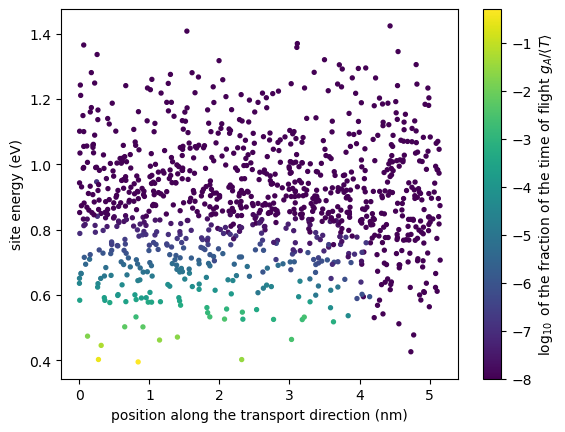

time of flight 3.93e-07 s
segment 19: x = 0.84 nm, energy 0.395 eV, 50% of the time of flight
segment 909: x = 0.27 nm, energy 0.403 eV, 30% of the time of flight
segment 995: x = 0.31 nm, energy 0.446 eV, 6% of the time of flight
segment 353: x = 2.32 nm, energy 0.402 eV, 3% of the time of flight
segment 70: x = 1.14 nm, energy 0.462 eV, 3% of the time of flight


In [8]:
grw = results("grw_results.dat")
occ = np.loadtxt("grw_occupation.dat", usecols=(0, 1, 2, 5))
segment, x, energy, fraction = occ.T
plt.scatter(x, energy, c=np.log10(np.maximum(fraction, 1e-8)), s=8, cmap="viridis")
plt.colorbar(label=r"$\log_{10}$ of the fraction of the time of flight $g_A/\langle T\rangle$")
plt.xlabel("position along the transport direction (nm)")
plt.ylabel("site energy (eV)")
plt.show()
order = np.argsort(fraction)[::-1][:5]
print(f"time of flight {grw['tau_mean']:.2e} s")
for s in order:
    print(f"segment {int(segment[s])}: x = {x[s]:.2f} nm, energy {energy[s]:.3f} eV, {fraction[s]:.0%} of the time of flight")

A handful of molecules hold the electron for most of the time of flight. These trap sites can be analysed further, e.g. by their conformation or environment; their identification from the occupation map needs no sampling.

`kmctof` simulates the same experiment; its mean transit time agrees with `grw` within the statistical error, and the distribution over runs shows how broad the transit times are:

KMC 3.71e-07 +- 1.0e-08 s, grw 3.93e-07 s


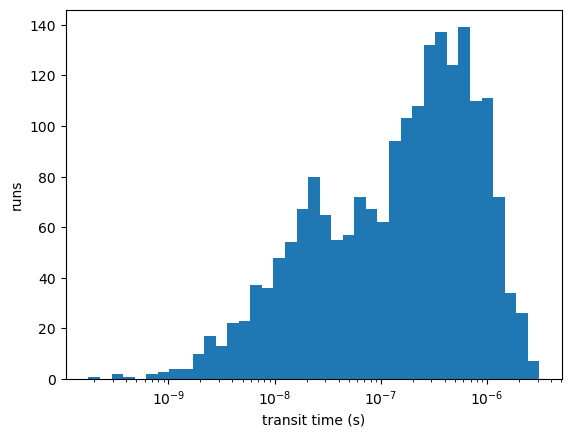

In [9]:
run('xtp_run -e kmctof -c carriertype=electron field="-1e7 0 0" runs=2000 -f state.hdf5')
tof = results("kmctof_results.dat")
print(f"KMC {tof['transit_mean']:.2e} +- {tof['transit_error']:.1e} s, grw {grw['tau_mean']:.2e} s")
transit = np.loadtxt("kmctof_runs.dat", usecols=5)
plt.hist(transit, bins=np.logspace(np.log10(transit.min()), np.log10(transit.max()), 40))
plt.xscale("log")
plt.xlabel("transit time (s)")
plt.ylabel("runs")
plt.show()

## Summary

* The energy landscape and the couplings of a morphology determine where carriers are trapped; `eanalyze` and `ianalyze` give a first impression.
* `kmcmultiple` gives bulk mobilities; its exact single-carrier values are cheap and free of statistical errors, and they are the reference for the KMC.
* `grw` and `kmctof` give times of flight; the occupation map of `grw` identifies the molecules that act as traps.

This morphology is small (1000 molecules, about 5 nm): mobilities from it are dominated by a few sites and should be taken as an illustration. Production calculations need larger systems and several snapshots.